# Augmented Social Scientist: train encoder models on a classification task

Companion notebook to the [tutorial](https://albandrp.github.io/encoder-classifier-tuto/): it runs the tutorial's code from top to bottom. Explanations are in the tutorial.

Install the environment first (Python 3.14):

```bash
pip install -qU pandas "transformers==4.52.4" datasets ipykernel matplotlib torch "accelerate>=0.26.0" scikit-learn plotly "nbformat>=4.2.0"
```

## Load and preprocess your data

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/yiweiluo/GWStance/refs/heads/master/3_stance_detection/1_MTurk/full_annotations.tsv"
df_raw = pd.read_csv(url, sep = "\t") # Careful here, this document is a tsv (separator="\t" and not a csv, separator = ",")

df_raw.head()

,Unnamed: 0,MACE_pred,av_rating,sentence,worker_0,worker_1,worker_2,worker_3,worker_4,worker_5,worker_6,worker_7,round,batch,sent_id,disagree,agree,neutral
0,0,disagrees,-1.000,Global warming is a hoax.,disagrees,disagrees,disagrees,disagrees,disagrees,disagrees,disagrees,disagrees,1,0,s0,NaN,NaN,NaN
1,1,neutral,0.375,Alarming levels of sea level rise are predicte...,neutral,neutral,neutral,agrees,agrees,neutral,neutral,agrees,1,0,s1,NaN,NaN,NaN
2,2,neutral,0.000,"Over the past several years, the United States...",neutral,neutral,neutral,neutral,neutral,neutral,neutral,neutral,1,0,s2,NaN,NaN,NaN
3,3,agrees,1.000,Global warming is happening and it will be dan...,agrees,agrees,agrees,agrees,agrees,agrees,agrees,agrees,1,0,s3,NaN,NaN,NaN
4,4,neutral,0.000,Some icebergs are cute.,neutral,neutral,neutral,neutral,neutral,neutral,neutral,neutral,1,0,s4,NaN,NaN,NaN


In [2]:
df = df_raw.loc[:,["sent_id", "sentence", "MACE_pred", "av_rating"]]
df = df.rename(columns={"MACE_pred" : "label_text"}) # Rename MACE_pred for conveniency
df

,sent_id,sentence,label_text,av_rating
0,s0,Global warming is a hoax.,disagrees,-1.000
1,s1,Alarming levels of sea level rise are predicte...,neutral,0.375
2,s2,"Over the past several years, the United States...",neutral,0.000
3,s3,Global warming is happening and it will be dan...,agrees,1.000
4,s4,Some icebergs are cute.,neutral,0.000
...,...,...,...,...
2295,t5,"Agriculture, in general, is responsible for a ...",neutral,0.375
2296,t6,"Hiring a White House ""climate change czar"" wou...",agrees,0.750
2297,t7,More carbon is being released than stored.,neutral,0.250
2298,t8,New laws are needed to crack down on climate a...,disagrees,-0.750


In [3]:
df.groupby(["label_text"]).size()

label_text
agrees       871
disagrees    441
neutral      988
dtype: int64

In [4]:
df["ID"] = [f'ID-{i:04}' for i in range(len(df))]

count    2300.000000
mean      109.890435
std        56.251317
min        21.000000
25%        70.000000
50%       100.000000
75%       145.000000
max       347.000000
Name: sentence-len, dtype: float64

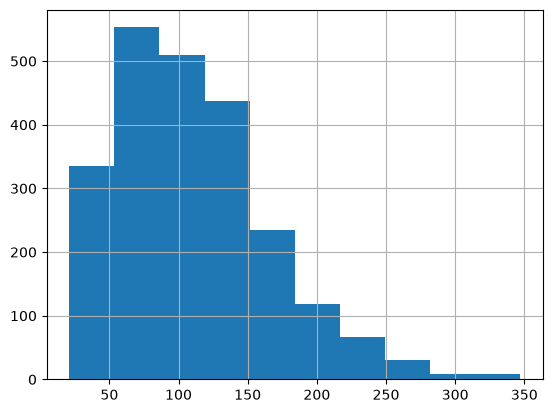

In [5]:
df["sentence-len"] = df["sentence"].apply(len)
df["sentence-len"].hist()
df["sentence-len"].describe()

In [6]:
def preprocess_text(text: str):
    if not(isinstance(text, str)):
        return pd.NA
    return (
        text
        .replace("``", '"')
        .replace("''", '"')
        .replace(" ,", ",")
        .replace(" .", ".")
        .replace(" !", "!")
        .replace(" ?", "?")
        .replace(" :", ":")
        .replace(" 's", "'s")
    )

df["sentence-preprocessed"] = df["sentence"].apply(preprocess_text)

In [7]:
df.groupby("sentence").size().value_counts()

1     2034
2        8
50       5
Name: count, dtype: int64

In [8]:
df_no_duplicates = df.loc[~df["sent_id"].str.startswith("s"), :]

### Remove the remaining duplicates

Detailed in the [appendices](https://albandrp.github.io/encoder-classifier-tuto/appendices.html#sec-duplicates).

In [9]:
df_concensus = df_no_duplicates.groupby("sentence")["label_text"].agg(concensus = lambda X : len(set(X)) == 1)
print(df_concensus[df_concensus["concensus"] == False])

                                                  concensus
sentence                                                   
We need to get rid of fossil fuel subsidies now.      False


In [10]:
df_no_duplicates = df_no_duplicates.loc[
    df_no_duplicates["sentence"] != "We need to get rid of fossil fuel subsidies now.",
    :
]
df_no_duplicates = df_no_duplicates.drop_duplicates("sentence")

In [11]:
last_duplicates = [
    ("Global warming isn’t happening.","Global warming isn't happening."),
    ("There is no solid evidence of global warming.","There is not solid evidence of global warming."),
    ("Balance of evidence suggests a discernible human influence on global climate.","The balance of evidence suggests a discernible human influence on global climate."),
    ("The alleged “ consensus ” behind the dangers of anthropogenic global warming is not nearly as settled among climate scientists as people imagine.","The alleged â consensus â behind the dangers of anthropogenic global warming is not nearly as settled among climate scientists as people imagine."),
    ("Rising global temperatures during the 19th and 20th centuries may be linked to greater plant photosynthesis.","Rising global temperatures during the 19th and 20th centuries could be linked to greater plant photosynthesis."),
    ("Climate change will continue to affect all types of weather phenomena and subsequently impact increasingly urbanised areas.","Climate change will continue to affect all types of weather phenomena and subsequently impact increasingly urbanized areas."),
]

for (s1, s2) in last_duplicates:
    lab_s1 = df_no_duplicates.loc[df_no_duplicates["sentence"] == s1, "label_text"]
    lab_s2 = df_no_duplicates.loc[df_no_duplicates["sentence"] == s2, "label_text"]
    if lab_s1.item() == lab_s2.item() : 
        df_no_duplicates = df_no_duplicates.drop(index = lab_s2.index)
    else: 
        df_no_duplicates = df_no_duplicates.drop(index = [*lab_s1.index, *lab_s2.index])

# Save the result, loaded in the tutorial as df_clean
df_no_duplicates.to_csv("./data/dataset-no-duplicates.csv", index = False)

In [12]:
df_clean = pd.read_csv("./data/dataset-no-duplicates.csv")
df_clean

,sent_id,sentence,label_text,av_rating,ID,sentence-len,sentence-preprocessed
0,t0,Warmer-than-normal sea surface temperatures ar...,agrees,0.625,ID-0005,170,Warmer-than-normal sea surface temperatures ar...
1,t1,We will continue to rely in part on fossil fue...,neutral,0.000,ID-0006,94,We will continue to rely in part on fossil fue...
2,t10,The actual rise in sea levels measured only 1....,neutral,0.000,ID-0007,118,The actual rise in sea levels measured only 1....
3,t11,Claims of global warming have been greatly exa...,disagrees,-1.000,ID-0008,55,Claims of global warming have been greatly exa...
4,t12,The Intergovernmental Panel on Climate Change ...,neutral,-0.125,ID-0009,173,The Intergovernmental Panel on Climate Change ...
...,...,...,...,...,...,...,...
2030,t5,"Agriculture, in general, is responsible for a ...",neutral,0.375,ID-2295,78,"Agriculture, in general, is responsible for a ..."
2031,t6,"Hiring a White House ""climate change czar"" wou...",agrees,0.750,ID-2296,64,"Hiring a White House ""climate change czar"" wou..."
2032,t7,More carbon is being released than stored.,neutral,0.250,ID-2297,42,More carbon is being released than stored.
2033,t8,New laws are needed to crack down on climate a...,disagrees,-0.750,ID-2298,107,New laws are needed to crack down on climate a...


In [13]:
from datasets import Dataset, DatasetDict

SEED = 2306406
ds = Dataset.from_pandas(df_clean)

temp = ds.train_test_split(test_size = 0.3, shuffle = True, seed = SEED)
ds_train = temp["train"]
temp = temp["test"].train_test_split(test_size = 0.5, shuffle = True, seed = SEED)
ds_valid = temp["train"]
ds_test = temp["test"]

dsd = DatasetDict({
  "train": ds_train,
  "valid": ds_valid,
  "test": ds_test
})

## Choose and load a model

In [14]:
from transformers import AutoModelForSequenceClassification, set_seed

set_seed(SEED) # The classifier layer is initialised randomly: fix the seed here too

labels = list(df["label_text"].unique())
num_labels = len(labels)
id2label = {id:label for id, label in enumerate(labels)}
label2id = {label:id  for id, label in enumerate(labels)}

MODEL_NAME = "google-bert/bert-base-uncased"
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [15]:
print(model)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((76

In [16]:
from transformers import AutoConfig
print(AutoConfig.from_pretrained(MODEL_NAME))

BertConfig {
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformers_version": "4.52.4",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}



### Tokenize the dataset

In [17]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [18]:
tokenizer("Hello World! 😇")
# {'input_ids': [101, 7592, ...], 'token_type_ids': [0, 0, ...], 'attention_mask': [1, 1, ...]}
tokenizer("Hello World! 😇").input_ids
# [101, 7592, 2088, 999, 100, 102] <- the token ids
tokenizer.decode([101, 7592, 2088, 999, 100, 102])
# '[CLS] hello world! [UNK] [SEP]'
# [CLS] is the starting token and [SEP] the terminating one.
# The smiley is marked as unknown [UNK]
tokenizer.decode([101])
# '[CLS]' <- token number 101
tokenizer.decode([2088, 999])
# 'world!' <- tokens number 2088 and 999
tokenizer(
  ["This sentence is very long. " * 20, # Very long
   "Short."],                           # Very short
  truncation = True,
  padding = "max_length",
  max_length = 50,
  return_tensors = "np"
).input_ids.shape
# (2, 50) <- long entries are truncated and short ones are padded so that all tokenized entries are the same length

(2, 50)

In [19]:
def preprocess_dataset(row: dict):
  tokenized_entry = tokenizer(
    row["sentence-preprocessed"],
    truncation = True,
    padding = "max_length",
    max_length = 400,
  )
  return {
      **row.copy(),
      "labels": int(label2id[row["label_text"]]),
      **tokenized_entry
  }

dsd = dsd.map(preprocess_dataset)
# Only keep columns useful for training
dsd = dsd.select_columns(['ID', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'])
# Set the dataset dict format to torch
dsd = dsd.with_format("torch")
dsd

Map:   0%|          | 0/1424 [00:00<?, ? examples/s]huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Map:  70%|███████   | 1000/1424 [00:00<00:00, 8268.83 examples/s]

Map: 100%|██████████| 1424/1424 [00:00<00:00, 7735.34 examples/s]

Map:   0%|          | 0/305 [00:00<?, ? examples/s]

Map: 100%|██████████| 305/305 [00:00<00:00, 11323.92 examples/s]

Map:   0%|          | 0/306 [00:00<?, ? examples/s]

Map: 100%|██████████| 306/306 [00:00<00:00, 11255.83 examples/s]

DatasetDict({
    train: Dataset({
        features: ['ID', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1424
    })
    valid: Dataset({
        features: ['ID', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 305
    })
    test: Dataset({
        features: ['ID', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 306
    })
})

### Setup fine-tuning hyperparameters

In [20]:
from transformers import TrainingArguments, Trainer
training_arguments = TrainingArguments(
    # Hyperparameters
    num_train_epochs = 5,
    learning_rate = 5e-5,
    weight_decay  = 0.0,
    optim = "adamw_torch_fused",
    # Second order hyperparameters
    per_device_train_batch_size = 4,
    per_device_eval_batch_size = 4,
    gradient_accumulation_steps = 8,
    # Pipe
    output_dir = "./models/training",
    eval_strategy = "steps"   , eval_steps    = 0.05,
    logging_strategy = "steps", logging_steps = 0.05,
    save_strategy = "steps"   , save_steps    = 0.05,
    load_best_model_at_end = True,
    save_total_limit = 2,
    seed = SEED,

    disable_tqdm = False,
)

### Launch fine-tuning

In [21]:
trainer = Trainer(
    model = model,
    args = training_arguments,
    train_dataset=dsd["train"],
    eval_dataset=dsd["valid"],
)

trainer.train()

Step,Training Loss,Validation Loss
12,1.012000,0.990742
24,1.002900,0.919349
36,0.928200,0.847436
48,0.773500,0.815246
60,0.719300,0.799047
72,0.617000,0.810569
84,0.609300,0.835269
96,0.553400,0.836401
108,0.442100,0.875192
120,0.340200,0.922197


TrainOutput(global_step=225, training_loss=0.4558756144841512, metrics={'train_runtime': 870.9428, 'train_samples_per_second': 8.175, 'train_steps_per_second': 0.258, 'total_flos': 1463568386112000.0, 'train_loss': 0.4558756144841512, 'epoch': 5.0})

In [22]:
reload_model = AutoModelForSequenceClassification.from_pretrained(
    trainer.state.best_model_checkpoint)

## Use model for inference and evaluate performance

In [23]:
import numpy as np
import torch
from tqdm import tqdm

IDs = []
y_gold = []
y_pred = []

# Reload the best model:
model = AutoModelForSequenceClassification.from_pretrained(trainer.state.best_model_checkpoint)
model.eval()

for batch in tqdm(dsd["valid"].iter(batch_size = 8)):
  IDs += [batch["ID"]]
  y_gold += [batch["labels"]]
  with torch.no_grad():
    logits = model(input_ids = batch["input_ids"], attention_mask = batch["attention_mask"]).logits.softmax(1).numpy()
    y_pred += [np.argmax(logits, axis=1)]
results = pd.DataFrame({
  "ID": np.concat(IDs),
  "gold": np.concat(y_gold),
  "pred": np.concat(y_pred)
})

0it [00:00, ?it/s]

1it [00:00,  2.24it/s]

2it [00:00,  2.32it/s]

3it [00:01,  2.35it/s]

4it [00:01,  2.37it/s]

5it [00:02,  2.38it/s]

... (30 outputs left out)

36it [00:15,  2.39it/s]

37it [00:15,  2.39it/s]

38it [00:15,  2.39it/s]

39it [00:15,  2.44it/s]

In [24]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true = results["gold"].map(id2label),
    y_pred = results["pred"].map(id2label)
))

              precision    recall  f1-score   support

      agrees       0.71      0.62      0.66       116
   disagrees       0.64      0.48      0.55        61
     neutral       0.66      0.82      0.73       128

    accuracy                           0.68       305
   macro avg       0.67      0.64      0.65       305
weighted avg       0.68      0.68      0.67       305



## Predict labels for the full dataset

In [25]:
# In your project: your unannotated texts, preprocessed and tokenized like dsd
ds_corpus = dsd["test"] # Stand-in for this notebook: replace with your own unannotated texts

IDs = []
y_pred = []
for batch in tqdm(ds_corpus.iter(batch_size = 8)):
  IDs += [batch["ID"]]
  with torch.no_grad():
    logits = model(input_ids = batch["input_ids"], attention_mask = batch["attention_mask"]).logits.softmax(1).numpy()
    y_pred += [np.argmax(logits, axis=1)]

predictions = pd.DataFrame({
  "ID": np.concat(IDs),
  "label_pred": pd.Series(np.concat(y_pred)).map(id2label)
})
predictions.to_csv("./outputs/predictions.csv", index = False)

0it [00:00, ?it/s]

1it [00:00,  2.39it/s]

2it [00:00,  2.39it/s]

3it [00:01,  2.39it/s]

4it [00:01,  2.39it/s]

5it [00:02,  2.39it/s]

... (31 outputs left out)

37it [00:15,  2.39it/s]

38it [00:15,  2.39it/s]

39it [00:16,  3.05it/s]

39it [00:16,  2.43it/s]

## Diagnose and fix training problems

In [26]:
import plotly.express as px

loss = []

for log in trainer.state.log_history:
    step = log["step"]
    if "loss" in log:
        loss += [{"step": step, "loss": log["loss"], "split": "train"}]
    elif "eval_loss" in log:
        loss += [{"step": step, "loss": log["eval_loss"], "split": "valid"}]
    else:
        print(log)

loss = pd.DataFrame(loss)

px.line(loss, x = "step", y = "loss", color =  "split")

{'train_runtime': 870.9428, 'train_samples_per_second': 8.175, 'train_steps_per_second': 0.258, 'total_flos': 1463568386112000.0, 'train_loss': 0.4558756144841512, 'epoch': 5.0, 'step': 225}


## Use GPU for faster training

In [27]:
from torch.cuda import is_available as cuda_available
from torch.mps import is_available as mps_available

print("CUDA: ", cuda_available())
print("MPS: ", mps_available())

CUDA:  False
MPS:  True


In [28]:
DEVICE = "cuda" if cuda_available() else "mps" if mps_available() else "cpu"

In [29]:
IDs = []
y_gold = []
y_pred = []

# Reload the best model:
model = AutoModelForSequenceClassification.from_pretrained(trainer.state.best_model_checkpoint)
model = model.to(device=DEVICE)
model.eval()
if DEVICE == "cuda": model = model.to(torch.bfloat16) # Only works on GPUs

for batch in tqdm(dsd["valid"].iter(batch_size = 8)):
  IDs += [batch["ID"]]
  y_gold += [batch["labels"].cpu()]
  with torch.no_grad():
    probs = (
      model(input_ids = batch["input_ids"].to(DEVICE), attention_mask = batch["attention_mask"].to(DEVICE))
      .logits.cpu().softmax(1).float().numpy()
    )
    y_pred += [np.argmax(probs, axis=1)]

results = pd.DataFrame({
  "ID": np.concat(IDs),
  "gold": np.concat(y_gold),
  "pred": np.concat(y_pred)
})

0it [00:00, ?it/s]

1it [00:00,  4.55it/s]

2it [00:00,  4.61it/s]

3it [00:00,  4.62it/s]

4it [00:00,  4.62it/s]

5it [00:01,  4.63it/s]

... (30 outputs left out)

36it [00:07,  4.72it/s]

37it [00:07,  4.72it/s]

38it [00:08,  4.72it/s]

39it [00:08,  4.78it/s]